In [ ]:
from scipy import stats
from numpy import mean, sqrt, exp, log
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

In [ ]:
M = 10
S = 3

sigma_log = sqrt(log(1 + (S * S) / (M * M)))  # примерно 0,29
mu_log = log(M) - (sigma_log * sigma_log / 2)  # примерно 2,26
m_log = exp(mu_log)  # примерно 9,58

lognormal_dist = stats.lognorm(s=sigma_log, scale=m_log)

сгенерируйте n = 10 значений случайной величины Т и на основе этих данных определите частоту  W(A) (статистическую вероятность) появления события А, равного
ожиданию 41 автобуса на остановке менее 5 минут (0 — событие не произошло, 1 — произошло)

In [3]:
n = 10

wait_time = lognormal_dist.rvs(size=n)

w_a = mean(wait_time < 5)  # можно применить среднее, т.к. оценка соответсвует 1 или 0

print(f"значения случайной величины Т: {wait_time}\n")
print(f"частота  W(A) появления события А: {w_a}")


значения случайной величины Т: [ 6.64934822 10.27519723  6.8386883   6.54641773  9.81956694  7.08187886
  8.92080765  8.90436443  6.19765306 11.38964636]

частота  W(A) появления события А: 0.0


In [4]:
# через cdf (функцию распределения) смотрим вероятность, что T <= 5
p_true = lognormal_dist.cdf(5)
print(f"истинное значение p: {p_true:.4f}")

истинное значение p: 0.0134


In [5]:
epsilon = 0.1

# формула 2*cdf(2 * sqrt(n) * epsilon) - 1 ограничивает площадь под кривой, в которой находится K

# так как Ф(x) ф-я стандартного нормального распределения
K = 2 * stats.norm.cdf(2 * sqrt(n) * epsilon) - 1

print(f"для n = {n} и epsilon = {epsilon} вероятность, что отклонение W(A) от p меньше epsilon, K = {K:.4f}")

для n = 10 и epsilon = 0.1 вероятность, что отклонение W(A) от p меньше epsilon, K = 0.4729


In [ ]:
N = 100
frequencies = []  # частоты 100 W(A)

for _ in range(N):
    wait_time = lognormal_dist.rvs(size=n)
    w_a = mean(wait_time < 5)
    frequencies.append(w_a)

# подсчет попаданий в диапазон +- epsilon
hits = sum(1 for w in frequencies if abs(w - p_true) < epsilon)
print(f"из {N} испытаний в диапазон попало: {hits}")
print(f"теоретическое ожидание (K * 100): {K * 100:.1f}")

из 100 испытаний в диапазон попало: 99
теоретическое ожидание (K * 100): 47.3


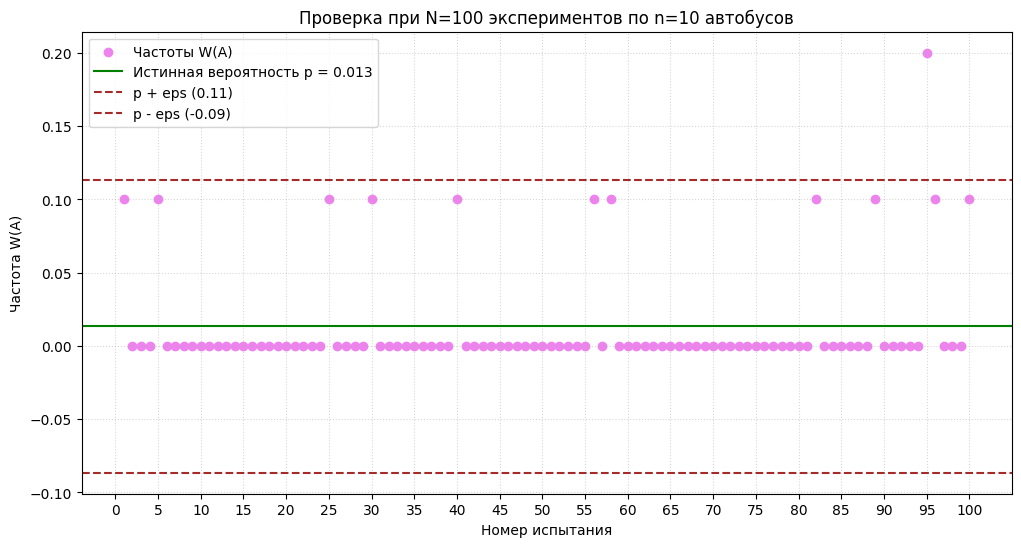

In [22]:
plt.figure(figsize=(12, 6))
plt.scatter(range(1, N + 1), frequencies, color='violet', label='Частоты W(A)')

# прямая y = p и две прямые y = p +- epsilon
plt.axhline(y=p_true, color='green', linestyle='-', label=f'Истинная вероятность p = {p_true:.3f}')
plt.axhline(y=p_true + epsilon, color='brown', linestyle='--', label=f'p + eps ({p_true + epsilon:.2f})')
plt.axhline(y=p_true - epsilon, color='brown', linestyle='--', label=f'p - eps ({p_true - epsilon:.2f})')
#plt.axhline(y=max(0, p_true - epsilon), color='brown', linestyle='--')

ax = plt.gca()
ax.yaxis.set_major_locator(MultipleLocator(0.05))
ax.xaxis.set_major_locator(MultipleLocator(5))

plt.xlabel('Номер испытания')
plt.ylabel('Частота W(A)')
plt.title(f'Проверка при N={N} экспериментов по n={n} автобусов')
plt.grid(True, which='both', linestyle=':', alpha=0.5)

plt.legend()
plt.show()

In [20]:
K = 0.9

# аргумент x через обратную функцию (ppf)
x_val = stats.norm.ppf((K + 1) / 2)

# формула выведена из данной в задании
n_required = round((x_val * x_val) / (4 * epsilon * epsilon), 3)

print(f"необходимое n: {n_required}\n")

new_frequencies = []
n_required_graph = 68  # округлила до целого для графика

for _ in range(N):
    wait_time = lognormal_dist.rvs(size=n_required_graph)
    w_a = mean(wait_time < 5)
    new_frequencies.append(w_a)

new_hits = sum(1 for w in new_frequencies if abs(w - p_true) < epsilon)
print(f"при n = {n_required} в диапазон попало: {new_hits} из {N}")

необходимое n: 67.639

при n = 67.639 в диапазон попало: 100 из 100


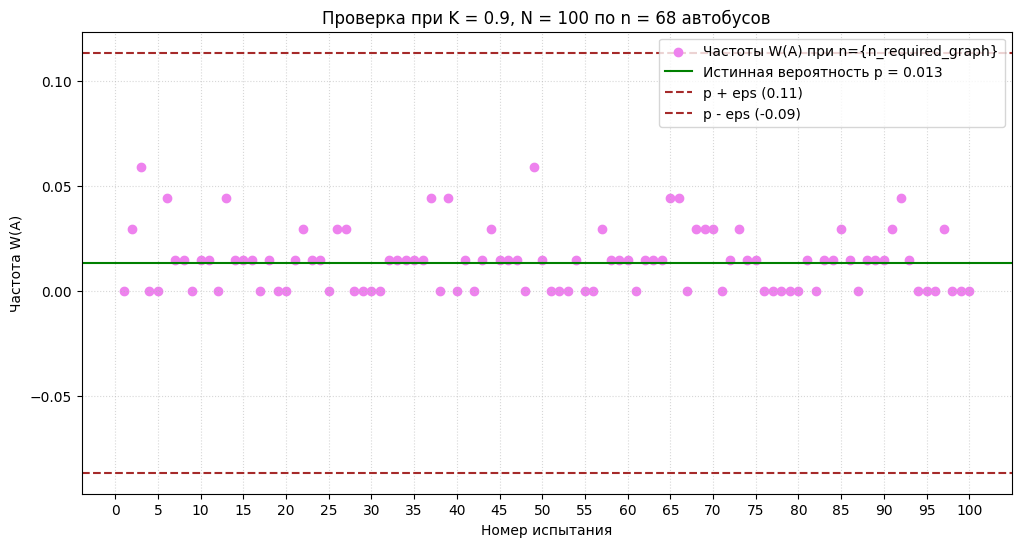

In [23]:
plt.figure(figsize=(12, 6))
plt.scatter(range(1, N + 1), new_frequencies, color='violet', label='Частоты W(A) при n={n_required_graph}')

# прямая y = p и две прямые y = p +- epsilon
plt.axhline(y=p_true, color='green', linestyle='-', label=f'Истинная вероятность p = {p_true:.3f}')
plt.axhline(y=p_true + epsilon, color='brown', linestyle='--', label=f'p + eps ({p_true + epsilon:.2f})')
plt.axhline(y=p_true - epsilon, color='brown', linestyle='--', label=f'p - eps ({p_true - epsilon:.2f})')
#plt.axhline(y=max(0, p_true - epsilon), color='brown', linestyle='--')

ax = plt.gca()
ax.yaxis.set_major_locator(MultipleLocator(0.05))
ax.xaxis.set_major_locator(MultipleLocator(5))

plt.xlabel('Номер испытания')
plt.ylabel('Частота W(A)')
plt.title(f'Проверка при K = 0.9, N = 100 по n = 68 автобусов')
plt.grid(True, which='both', linestyle=':', alpha=0.5)

plt.legend()
plt.show()

Как изменится вероятность K, если уменьшить epsilon? Уменьшится как функция от аргумента меньше, так и логически в диапазон меньше сложнее попасть

Как изменится вероятность K, если уменьшить n? Уменьшится как функция от аргумента меньше, увеличтся влияние случайности, надежность прогноза станет также меньше